## SVM model

In [1]:
# Step 1: Import required lib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 


In [2]:
# Step 2: load the dataset
df = pd.read_csv("SVM_Dataset.csv")

In [3]:
# Step 3: Data Exploration
df.head()

,buying,maint,doors,persons,lug_boot,safety,car
0,vhigh,vhigh,two,two,small,low,unacc
1,vhigh,vhigh,two,two,small,med,unacc
2,vhigh,vhigh,two,two,small,high,unacc
3,vhigh,vhigh,two,two,med,low,unacc
4,vhigh,vhigh,two,two,med,med,unacc


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1728 entries, 0 to 1727
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   buying    1728 non-null   object
 1   maint     1728 non-null   object
 2   doors     1728 non-null   object
 3   persons   1728 non-null   object
 4   lug_boot  1728 non-null   object
 5   safety    1728 non-null   object
 6   car       1728 non-null   object
dtypes: object(7)
memory usage: 94.6+ KB


In [6]:
for col in df.columns:
    print(f"Column: {col}")
    print(f"Unique Values: {df[col].unique()}")
    print(f"Missing Values: {df[col].isnull().sum()}")
    print("-" * 30)

Column: buying
Unique Values: ['vhigh' 'high' 'med' 'low']
Missing Values: 0
------------------------------
Column: maint
Unique Values: ['vhigh' 'high' 'med' 'low']
Missing Values: 0
------------------------------
Column: doors
Unique Values: ['two' 'three' 'four' '5more']
Missing Values: 0
------------------------------
Column: persons
Unique Values: ['two' 'four' 'more']
Missing Values: 0
------------------------------
Column: lug_boot
Unique Values: ['small' 'med' 'big']
Missing Values: 0
------------------------------
Column: safety
Unique Values: ['low' 'med' 'high']
Missing Values: 0
------------------------------
Column: car
Unique Values: ['unacc' 'acc' 'vgood' 'good']
Missing Values: 0
------------------------------


In [7]:
df['lug_boot'].replace({'small': 0, 'med': 1, 'big': 2}, inplace=True)
df['safety'].replace({'low':0,'med':1,'high':2}, inplace=True)

C:\Users\ssart\AppData\Local\Temp\ipykernel_9144\1578383529.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['lug_boot'].replace({'small': 0, 'med': 1, 'big': 2}, inplace=True)
C:\Users\ssart\AppData\Local\Temp\ipykernel_9144\1578383529.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['safety'].replace({'low':0,'med':1,'high':2}, inplace=True)


In [8]:
df.head()

,buying,maint,doors,persons,lug_boot,safety,car
0,vhigh,vhigh,two,two,0,0,unacc
1,vhigh,vhigh,two,two,0,1,unacc
2,vhigh,vhigh,two,two,0,2,unacc
3,vhigh,vhigh,two,two,1,0,unacc
4,vhigh,vhigh,two,two,1,1,unacc


In [9]:
cat_columns  = ['buying', 'maint', 'doors', 'persons']

from sklearn.preprocessing import OneHotEncoder

# create the instance of model 
encoder = OneHotEncoder(sparse_output=False, drop='first')

# fit and transform the data
encoded_data = encoder.fit_transform(df[cat_columns])

In [14]:
# option 2: using pandas get_dummies
encoded_df = pd.get_dummies(df[cat_columns], drop_first=True)
encoded_df

,buying_low,buying_med,buying_vhigh,maint_low,maint_med,maint_vhigh,doors_four,doors_three,doors_two,persons_more,persons_two
0,False,False,True,False,False,True,False,False,True,False,True
1,False,False,True,False,False,True,False,False,True,False,True
2,False,False,True,False,False,True,False,False,True,False,True
3,False,False,True,False,False,True,False,False,True,False,True
4,False,False,True,False,False,True,False,False,True,False,True
...,...,...,...,...,...,...,...,...,...,...,...
1723,True,False,False,True,False,False,False,False,False,True,False
1724,True,False,False,True,False,False,False,False,False,True,False
1725,True,False,False,True,False,False,False,False,False,True,False
1726,True,False,False,True,False,False,False,False,False,True,False


In [16]:
# create a new dataframe with encoded df
df = pd.concat([df.drop(cat_columns, axis=1), encoded_df], axis=1)
df.head()


,lug_boot,safety,car,buying_low,buying_med,buying_vhigh,maint_low,maint_med,maint_vhigh,doors_four,...,buying_med,buying_vhigh,maint_low,maint_med,maint_vhigh,doors_four,doors_three,doors_two,persons_more,persons_two
0,0,0,unacc,False,False,True,False,False,True,False,...,False,True,False,False,True,False,False,True,False,True
1,0,1,unacc,False,False,True,False,False,True,False,...,False,True,False,False,True,False,False,True,False,True
2,0,2,unacc,False,False,True,False,False,True,False,...,False,True,False,False,True,False,False,True,False,True
3,1,0,unacc,False,False,True,False,False,True,False,...,False,True,False,False,True,False,False,True,False,True
4,1,1,unacc,False,False,True,False,False,True,False,...,False,True,False,False,True,False,False,True,False,True


In [17]:
df['car'].replace({'unacc':0,'acc':1,'good':2,'vgood':3}, inplace=True)

C:\Users\ssart\AppData\Local\Temp\ipykernel_9144\2817588286.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['car'].replace({'unacc':0,'acc':1,'good':2,'vgood':3}, inplace=True)


In [19]:
df['car'].value_counts()

car
0    1210
1     384
2      69
3      65
Name: count, dtype: int64

In [20]:
# divide the dataset into features and target variable
X = df.drop('car', axis=1)
y = df['car']

In [21]:
# handling class imbalance using oversampling technique SMOTE (Synthetic Minority Over-sampling Technique)
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_resampled, y_resampled = smote.fit_resample(X, y)



In [22]:
y_resampled.value_counts()

car
0    1210
1    1210
3    1210
2    1210
Name: count, dtype: int64

In [23]:
# split the dataset into training and testing sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X_resampled, y_resampled, test_size=0.2, random_state=42)

In [41]:
from sklearn.svm import SVC

# create an instance of the SVM model
svm_model = SVC(kernel='poly', degree=5, random_state=42)   

# fit the model on the training data
svm_model.fit(X_train, y_train)

y_pred = svm_model.predict(X_test)

In [42]:
# model evaluation
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

#find the accuracy of the model
accuracy = accuracy_score(y_test, y_pred)


# find the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# find the classification report
cr = classification_report(y_test, y_pred)

#print the accuracy, confusion matrix and classification report
print(f"Accuracy: {accuracy}")
print(f"Confusion Matrix: \n{cm}")
print(f"Classification Report: \n{cr}")

Accuracy: 0.9390495867768595
Confusion Matrix: 
[[249  15   1   0]
 [ 12 206  22   2]
 [  0   4 222   0]
 [  0   3   0 232]]
Classification Report: 
              precision    recall  f1-score   support

           0       0.95      0.94      0.95       265
           1       0.90      0.85      0.88       242
           2       0.91      0.98      0.94       226
           3       0.99      0.99      0.99       235

    accuracy                           0.94       968
   macro avg       0.94      0.94      0.94       968
weighted avg       0.94      0.94      0.94       968



C:\Users\ssart\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


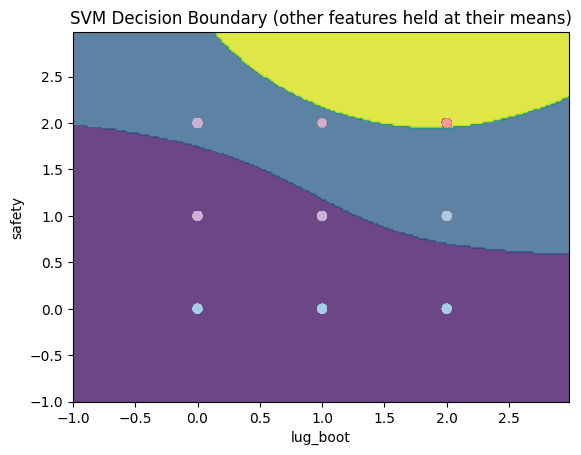

InvalidIndexError: (slice(None, None, None), 1)

In [45]:
import numpy as np

# make the plot of boundary of the SVM model
import matplotlib.pyplot as plt

# create a mesh to plot the decision boundary
h = 0.02
import matplotlib.pyplot as plt

# Use the first two features as the plot axes
X_values = X_train.to_numpy(dtype=float)
x_min, x_max = X_values[:, 0].min() - 1, X_values[:, 0].max() + 1
y_min, y_max = X_values[:, 1].min() - 1, X_values[:, 1].max() + 1

h = 0.02
xx, yy = np.meshgrid(
    np.arange(x_min, x_max, h),
    np.arange(y_min, y_max, h)
)

# Keep the other features fixed at their training-set means
grid = np.tile(X_values.mean(axis=0), (xx.size, 1))
grid[:, 0] = xx.ravel()
grid[:, 1] = yy.ravel()

Z = svm_model.predict(grid).reshape(xx.shape)

plt.contourf(xx, yy, Z, alpha=0.8)
plt.scatter(X_values[:, 0], X_values[:, 1], c=y_train, cmap=plt.cm.Paired)
plt.xlabel(X_train.columns[0])
plt.ylabel(X_train.columns[1])
plt.title('SVM Decision Boundary (other features held at their means)')
plt.show()
y_min, y_max = X_train[:, 1].min() - 1, X_train[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                    np.arange(y_min, y_max, h))

# make predictions on the mesh
Z = svm_model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# plot the decision boundary
plt.contourf(xx, yy, Z, alpha=0.8)
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap=plt.cm.Paired)
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('SVM Decision Boundary')
plt.show()